In [ ]:
#import libraries
import pandas as pd
import numpy as np

data = pd.read_csv("iris.csv")

print(data.head())
print(data.shape)
print(data.info())
print(data.isnull().sum())
print(data.describe())
print(data.columns)


   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa
(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
       sepal_length  sepal_width  petal_le

In [ ]:
#preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Remove unnecessary ID column if present
data = data.drop(columns=["Id"], errors="ignore")

# Separate input and target
X = data.drop("species", axis=1)
y = data["species"]

# Identify numerical and categorical features
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numerical_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (120, 4)
Testing: (30, 4)


In [ ]:
#Step 3: Classification algorithms
#1. Logistic Regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]


In [ ]:
#2. K-Nearest Neighbors (KNN)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", KNeighborsClassifier(n_neighbors=5))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [ ]:
#3. Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", DecisionTreeClassifier(random_state=42))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [ ]:
#4. Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", RandomForestClassifier(
        n_estimators=100, random_state=42
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



In [ ]:
#5. Support Vector Machine (SVM)

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", SVC(kernel="rbf"))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
#6. Naive Bayes

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report

model = Pipeline([
    ("preprocessing", preprocessor),
    ("algorithm", GaussianNB())
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9666666666666667
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [ ]:
#Simple linear Regression

import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd

# Load dataset
diabetes = load_diabetes(as_frame=True)

# Take one feature
X = diabetes.data[["bmi"]]
y = diabetes.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE Score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Actual vs Predicted
result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(result.head(10))

MAE: 52.259976445345536
MSE: 4061.8259284949268
RMSE Score: 63.73245584860925
R2 Score: 0.23335039815872138
   Actual   Predicted
0   219.0  145.806227
1    70.0  188.857390
2   202.0  147.958785
3   230.0  203.925298
4   111.0  131.814599
5    84.0  127.509482
6   242.0  322.315998
7   272.0  197.467623
8    94.0   61.856458
9    96.0  167.331809


In [ ]:
#multi linear regression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import pandas as pd

# Load dataset
diabetes = load_diabetes(as_frame=True)

# Take all features
X = diabetes.data
y = diabetes.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE Score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Display coefficients
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

# Actual vs Predicted
result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(result.head(10))

MAE: 42.79409467959994
MSE: 2900.1936284934814
RMSE Score: 53.85344583676593
R2 Score: 0.4526027629719195
Intercept: 151.34560453985995
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
   Actual   Predicted
0   219.0  139.547558
1    70.0  179.517208
2   202.0  134.038756
3   230.0  291.417029
4   111.0  123.789659
5    84.0   92.172347
6   242.0  258.232389
7   272.0  181.337321
8    94.0   90.224113
9    96.0  108.633759


MAE: 6.006414772521424
MSE: 61.9633045039498
RMSE Score: 7.87167736279567
R2 Score: 0.991867007010529


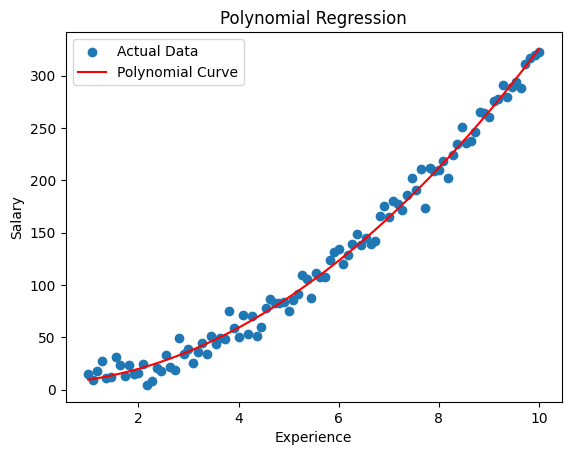

In [ ]:
#polynomial regression
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Generate sample data
np.random.seed(42)

X = np.linspace(1, 10, 100).reshape(-1, 1)

y = 5 + 2*X.flatten() + 3*(X.flatten()**2) + np.random.randn(100)*10

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Convert input features into polynomial features
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train_poly, y_train)

# Prediction
y_pred = model.predict(X_test_poly)

# Evaluation
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE Score:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

# Visualize
X_curve = np.linspace(1, 10, 100).reshape(-1, 1)

X_curve_poly = poly.transform(X_curve)

y_curve = model.predict(X_curve_poly)

plt.scatter(X, y, label="Actual Data")
plt.plot(X_curve, y_curve, color="red", label="Polynomial Curve")

plt.xlabel("Experience")
plt.ylabel("Salary")
plt.title("Polynomial Regression")
plt.legend()
plt.show()

Cluster Centers:
[[-2.63323268  9.04356978]
 [-6.88387179 -6.98398415]
 [ 4.74710337  2.01059427]]
Silhouette Score: 0.8480303059596955


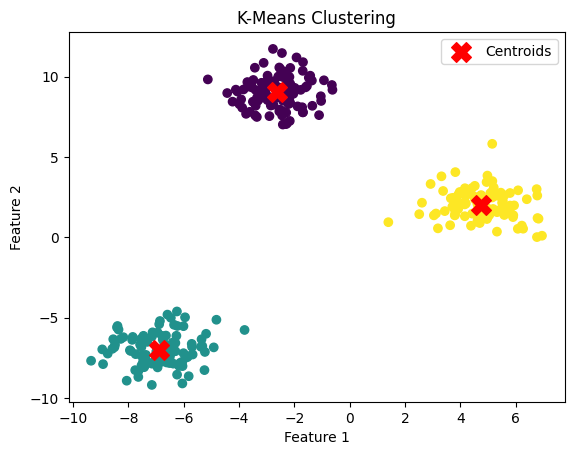

In [ ]:
#K-means
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Generate sample dataset
X, y = make_blobs(
    n_samples=300,
    centers=3,
    cluster_std=1.0,
    random_state=42
)

# Create K-Means model
model = KMeans(n_clusters=3, random_state=42, n_init=10)

# Train model and predict clusters
labels = model.fit_predict(X)

# Display cluster centers
print("Cluster Centers:")
print(model.cluster_centers_)

#evaluation
score = silhouette_score(X, labels)
print("Silhouette Score:", score)

# Visualize clusters
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="viridis")
plt.scatter(
    model.cluster_centers_[:, 0],
    model.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Cluster Labels:
[0 0 2 1 0 1 2 1 2 2 2 1 2 2 0 2 0 1 2 2 2 2 1 0 2 0 0 1 1 2 2 2 0 2 0 2 0
 1 0 1 1 2 0 1 2 2 0 1 0 1 1 0 0 2 0 1 0 2 1 2 0 1 1 0 0 1 1 0 0 2 1 0 0 2
 2 0 0 1 2 1 2 2 0 2 1 0 0 2 1 2 0 2 0 2 2 0 0 2 0 0 1 2 1 2 2 2 2 2 1 0 1
 2 2 2 2 1 0 1 0 1 1 1 2 0 0 0 0 2 0 0 2 2 2 2 2 1 1 0 2 0 2 2 0 2 1 1 1 2
 1 2 2 0 1 0 2 1 1 0 0 2 2 0 0 0 2 0 1 2 2 2 2 2 1 2 1 1 1 2 1 1 0 2 0 1 1
 0 1 2 1 1 0 0 1 0 1 1 1 1 2 0 2 2 1 1 2 1 0 0 1 2 2 0 1 1 0 0 0 0 2 0 0 1
 0 0 2 1 0 0 1 2 2 0 2 0 1 1 0 1 0 0 0 1 1 2 0 1 1 1 0 1 0 1 0 1 1 0 1 2 0
 2 2 2 0 2 1 1 0 1 1 2 2 1 1 1 0 0 0 2 2 2 1 1 1 1 0 1 0 1 1 0 2 1 1 2 0 2
 1 2 0 0]
Silhouette Score: 0.8480303059596955


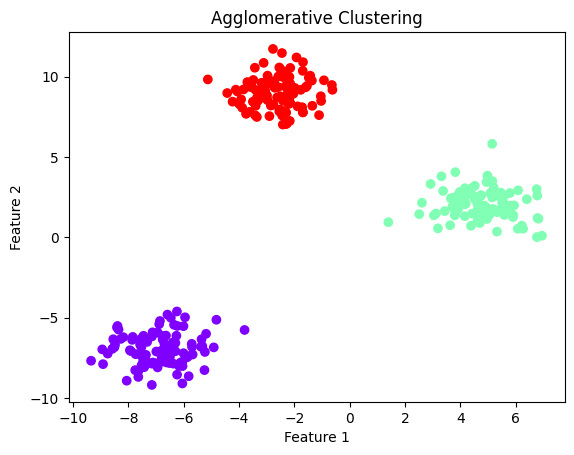

In [ ]:
#Hirarichal
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

# Generate dataset
X, y = make_blobs(
    n_samples=300,
    centers=3,
    random_state=42
)

# Create model
model = AgglomerativeClustering(n_clusters=3)

# Fit and predict
labels = model.fit_predict(X)

print("Cluster Labels:")
print(labels)

#evaluation
score = silhouette_score(X, labels)
print("Silhouette Score:", score)

# Visualize
plt.scatter(X[:, 0], X[:, 1], c=labels, cmap="rainbow")

plt.title("Agglomerative Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()